<a href="https://colab.research.google.com/github/Gagandeep1227/ML-2/blob/main/Bayesian_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install pandas pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 7.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


In [10]:
import pandas as pd
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

data = {
    'Weather': [
        'Sunny', 'Sunny', 'Rainy', 'Rainy',
        'Cloudy', 'Cloudy', 'Sunny', 'Rainy',
        'Cloudy', 'Sunny', 'Rainy', 'Cloudy'
    ],

    'Temperature': [
        'Hot', 'Hot', 'Cool', 'Cool',
        'Mild', 'Mild', 'Mild', 'Hot',
        'Cool', 'Cool', 'Mild', 'Hot'
    ],

    'Play': [
        'No', 'No', 'Yes', 'Yes',
        'Yes', 'Yes', 'Yes', 'No',
        'Yes', 'Yes', 'No', 'Yes'
    ]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

model = DiscreteBayesianNetwork([
    ('Weather', 'Play'),
    ('Temperature', 'Play')
])

model.fit(df)

print("\nModel Valid:", model.check_model())

inference = VariableElimination(model)

result = inference.query(
    variables=['Play'],
    evidence={
        'Weather': 'Sunny',
        'Temperature': 'Cool'
    }
)

print("\nProbability of Playing Cricket:")
print(result)

probability = result.values[
    list(result.state_names['Play']).index('Yes')
]

print("\nLikelihood of Playing Cricket:",
      round(probability * 100, 2), "%")

if probability >= 0.5:
    print("Prediction: Cricket can be played.")
else:
    print("Prediction: Cricket should not be played.")

Dataset:
   Weather Temperature Play
0    Sunny         Hot   No
1    Sunny         Hot   No
2    Rainy        Cool  Yes
3    Rainy        Cool  Yes
4   Cloudy        Mild  Yes
5   Cloudy        Mild  Yes
6    Sunny        Mild  Yes
7    Rainy         Hot   No
8   Cloudy        Cool  Yes
9    Sunny        Cool  Yes
10   Rainy        Mild   No
11  Cloudy         Hot  Yes

Model Valid: True

Probability of Playing Cricket:
+-----------+-------------+
| Play      |   phi(Play) |
+===========+=============+
| Play(No)  |      0.0000 |
+-----------+-------------+
| Play(Yes) |      1.0000 |
+-----------+-------------+

Likelihood of Playing Cricket: 100.0 %
Prediction: Cricket can be played.


In [6]:
pip install pandas numpy matplotlib scikit-learn pgmpy

Loading dataset...

Dataset Loaded Successfully!
Dataset Shape: (297, 14)

First 5 Records:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   69    1   0       160   234    1        2      131      0      0.1      1   
1   69    0   0       140   239    0        0      151      0      1.8      0   
2   66    0   0       150   226    0        0      114      0      2.6      2   
3   65    1   0       138   282    1        2      174      0      1.4      1   
4   64    1   0       110   211    0        2      144      1      1.8      1   

   ca  thal  target  
0   1     0       0  
1   2     0       0  
2   0     0       0  
3   1     0       1  
4   0     0       0  

Bayesian Network Created Successfully!
Model Valid: True

Patient Information:
{'age': 'Medium', 'cp': '3', 'chol': 'High', 'thalach': 'High', 'exang': '0'}

Heart Disease Probability:
+-------------+---------------+
| target      |   phi(target) |
+=============+===============+
| targe

/tmp/ipykernel_3807/1405725860.py:69: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(model, data)


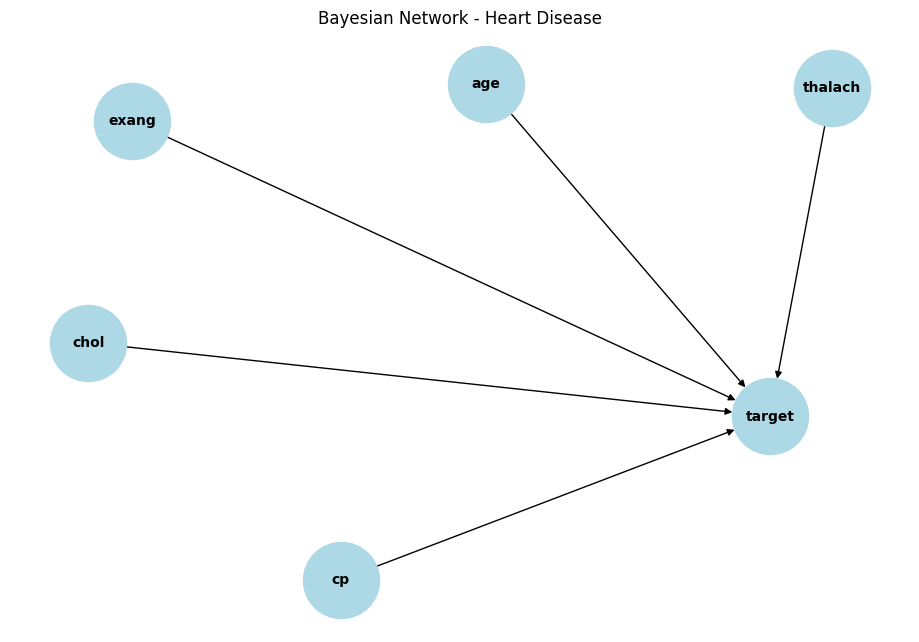


Dataset Summary:
         age   cp    chol thalach exang target
count    297  297     297     297   297    297
unique     3    4       3       3     2      2
top     High    3  Medium     Low     0     No
freq      99  142      99      99   200    160

PROGRAM EXECUTED SUCCESSFULLY!


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

print("Loading dataset...")

df = pd.read_csv("/content/heart_cleveland_upload.csv")

df.columns = df.columns.str.strip().str.lower()

df = df.rename(columns={
    "condition": "target",
    "output": "target",
    "thalachh": "thalach",
    "trtbps": "trestbps",
    "caa": "ca",
    "thall": "thal",
    "slp": "slope"
})

print("\nDataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())

features = ["age", "cp", "chol", "thalach", "exang"]

required = features + ["target"]

if not all(col in df.columns for col in required):
    raise ValueError(
        f"Required columns are missing. Expected {required}, but got {list(df.columns)}"
    )

data = df[required].copy()

for col in required:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna()

data["target"] = np.where(
    data["target"] > 0, "Yes", "No"
)

for col in ["age", "chol", "thalach"]:
    data[col] = pd.qcut(
        data[col].rank(method="first"),
        q=3,
        labels=["Low", "Medium", "High"]
    ).astype(str)

for col in ["cp", "exang"]:
    data[col] = data[col].astype(int).astype(str)

model = DiscreteBayesianNetwork([
    ("age", "target"),
    ("cp", "target"),
    ("chol", "target"),
    ("thalach", "target"),
    ("exang", "target")
])

estimator = BayesianEstimator(model, data)
cpds = estimator.get_parameters(prior_type="BDeu", equivalent_sample_size=10)
for cpd in cpds:
    model.add_cpds(cpd)

print("\nBayesian Network Created Successfully!")

print("Model Valid:", model.check_model())

inference = VariableElimination(model)

evidence = {
    "age": "Medium",
    "cp": "3",
    "chol": "High",
    "thalach": "High",
    "exang": "0"
}

print("\nPatient Information:")
print(evidence)

result = inference.query(
    variables=["target"],
    evidence=evidence,
    show_progress=False
)

print("\nHeart Disease Probability:")
print(result)

probability = result.values[
    list(result.state_names["target"]).index("Yes")
]

print(
    "\nLikelihood of Heart Disease:",
    round(probability * 100, 2), "%"
)

if probability >= 0.5:
    print("Prediction: Higher estimated probability")
else:
    print("Prediction: Lower estimated probability")

import networkx as nx

plt.figure(figsize=(9, 6))

graph = nx.DiGraph()
graph.add_edges_from(model.edges())

pos = nx.spring_layout(graph, seed=42)

nx.draw(
    graph,
    pos,
    with_labels=True,
    node_size=3000,
    node_color="lightblue",
    font_size=10,
    font_weight="bold",
    arrows=True
)

plt.title("Bayesian Network - Heart Disease")
plt.show()

print("\nDataset Summary:")
print(data.describe(include="all"))

print("\nPROGRAM EXECUTED SUCCESSFULLY!")